# 02 - Training dan Evaluasi Model P(berhasil)

Tujuan: memilih model v1 yang memprediksi **P(berhasil)** untuk pasangan (kebutuhan, vendor), lalu menguji apakah
ranking berbasis model menemukan vendor yang lebih baik daripada strategi **pilih termurah**.

Seluruh logika ada di [`training/train.py`](../training/train.py) (dipanggil di sini) supaya hasil notebook sama dengan
artefak `models/model.joblib`.

| Langkah | Rincian |
|---|---|
| Split waktu | train: bulan 1–18 (Okt 2024 – Mar 2026), test: bulan 19–24 (Apr – Sep 2026) |
| Preprocessing | numerik → StandardScaler; `qty`, `moq`, `rasio_qty`, `jumlah_transaksi`, `hari_sejak_pesanan_terakhir` → log1p + scaler; `kategori` → one-hot |
| Model | baseline rata-rata historis, Logistic Regression, Random Forest, LightGBM |
| Tuning | GridSearchCV + TimeSeriesSplit (4 lipatan) **hanya di data train** |
| Pemilihan | ROC-AUC validasi silang tertinggi; jika selisih < 0,005 pilih yang lebih sederhana |
| Evaluasi | ROC-AUC, Brier, log loss di test; NDCG@3 dan Top-1 hit terhadap ground truth generator |
| Model akhir | konfigurasi terpilih dilatih ulang pada seluruh data bulan 1–24 |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_curve

from core.features import FEATURE_COLUMNS
from core.ranking import recommend
from training.models import MODEL_LABELS
from training.train import run

S1, S2, S3, S4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"  # slot kategorikal 1-4 (urutan tetap)
INK, INK2, GRID, MUTED = "#0b0b0b", "#52514e", "#e6e5e0", "#8f8e88"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 2, "font.size": 10, "figure.dpi": 110,
    "legend.frameon": False,
})
COLORS = {"baseline": MUTED, "logreg": S1, "random_forest": S2, "lightgbm": S3}
pd.set_option("display.precision", 4)

out = run(save=True, data_dir=ROOT / "data", verbose=False)
print("Model terpilih:", out["selected"], "| versi:", out["artifact"]["version"])
out["summary"]["split"]

Model terpilih: random_forest | versi: v1-random_forest


{'train_until': '2026-04-01',
 'n_train': 4492,
 'n_test': 1583,
 'n_eval_needs': 1464,
 'n_eval_candidates': 8570}

## 1. Pipeline preprocessing

In [2]:
out["fitted"]["logreg"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['qty','hari_tersedia','kelonggaran_waktu',...,'berhasil_musim_ramai', 'jumlah_transaksi','hari_sejak_pesanan_terakhir']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('skew', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By

## 2. Validasi silang berbasis waktu (data train)

In [3]:
cv = out["cv_table"].assign(model=lambda d: d["model"].map(MODEL_LABELS))
cv

,model,cv_roc_auc,cv_std,best_params
0,Baseline (rata-rata historis),0.6500,0.0331,{}
1,Logistic Regression,0.7779,0.0261,{'C': 0.03}
2,Random Forest,0.7964,0.0124,"{'max_features': 0.5, 'min_samples_leaf': 20}"
3,LightGBM,0.7929,0.0132,"{'min_child_samples': 50, 'n_estimators': 200,..."


## 3. Metrik probabilitas di data test

Baris **oracle** memakai P(berhasil) sebenarnya dari generator. Hasil pengiriman diundi secara acak, sehingga
ini adalah **batas atas** yang tidak bisa dilewati model mana pun di data ini.

In [4]:
tt = out["test_table"].copy()
tt["model"] = tt["model"].map(MODEL_LABELS | {"oracle": "Oracle (P sebenarnya)"})
tt

,model,roc_auc,brier,log_loss
0,Baseline (rata-rata historis),0.6247,0.1629,0.5043
1,Logistic Regression,0.8127,0.1323,0.4099
2,Random Forest,0.8129,0.1287,0.4060
3,LightGBM,0.8194,0.1278,0.4009
4,Oracle (P sebenarnya),0.8395,0.1215,0.3807


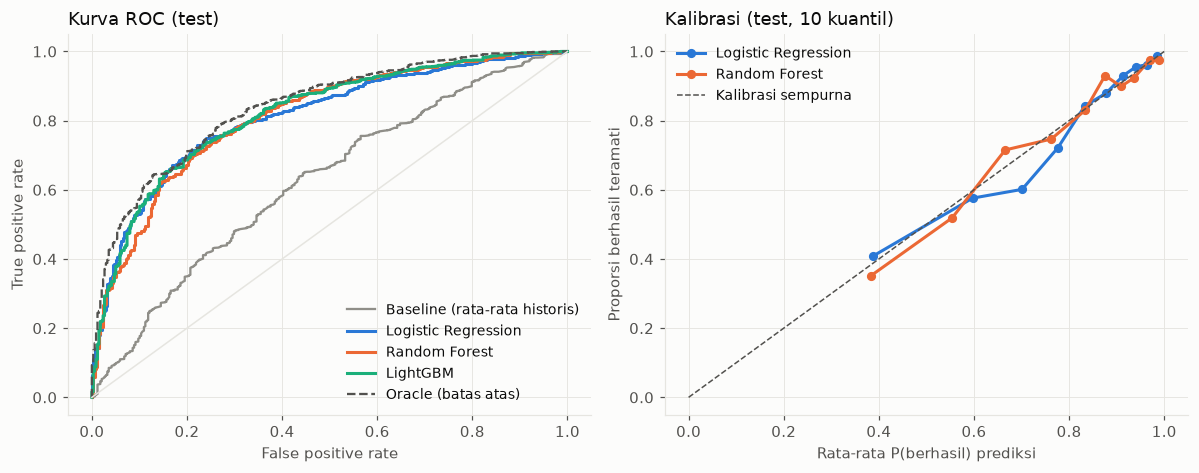

In [5]:
y = out["test"]["berhasil"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for name in ["baseline", "logreg", "random_forest", "lightgbm"]:
    fpr, tpr, _ = roc_curve(y, out["test_pred"][name])
    axes[0].plot(fpr, tpr, color=COLORS[name], label=MODEL_LABELS[name], lw=2 if name != "baseline" else 1.5)
fpr, tpr, _ = roc_curve(y, out["test_pred"]["oracle"])
axes[0].plot(fpr, tpr, color=INK2, ls="--", lw=1.5, label="Oracle (batas atas)")
axes[0].plot([0, 1], [0, 1], color=GRID, lw=1)
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("Kurva ROC (test)", loc="left"); axes[0].legend(loc="lower right", fontsize=9)

for name in ["logreg", out["selected"]] if out["selected"] != "logreg" else ["logreg"]:
    frac, mean_pred = calibration_curve(y, out["test_pred"][name], n_bins=10, strategy="quantile")
    axes[1].plot(mean_pred, frac, color=COLORS[name], marker="o", markersize=5, label=MODEL_LABELS[name])
axes[1].plot([0, 1], [0, 1], color=INK2, ls="--", lw=1, label="Kalibrasi sempurna")
axes[1].set_xlabel("Rata-rata P(berhasil) prediksi"); axes[1].set_ylabel("Proporsi berhasil teramati")
axes[1].set_title("Kalibrasi (test, 10 kuantil)", loc="left"); axes[1].legend(loc="upper left", fontsize=9)
fig.tight_layout()

## 4. Evaluasi ranking

Untuk setiap kebutuhan di periode test, **semua** kandidat yang lolos saringan diberi P(berhasil) sebenarnya oleh
generator. Relevansi kandidat = skor berbobot preset dengan P sebenarnya. Strategi "Sempurna" adalah batas atas
(NDCG = 1, Top-1 = 100%).

- **NDCG@3**: kualitas 3 teratas (gain = relevansi − relevansi terendah dalam kebutuhan).
- **Top-1 hit**: pilihan #1 = kandidat terbaik sebenarnya.
- **p_berhasil_pilihan1**: P(berhasil) sebenarnya dari pilihan #1 (rata-rata).
- **harga_pilihan1_vs_termurah**: harga pilihan #1 dibanding kandidat termurah (1,10 = 10% lebih mahal).

In [6]:
rk = out["ranking_table"]
print(out["summary"]["split"]["n_eval_needs"], "kebutuhan,", out["summary"]["split"]["n_eval_candidates"], "pasangan kandidat")
rk.set_index(["preset", "strategi"])

1464 kebutuhan, 8570 pasangan kandidat


ndcg@3  top1_hit  regret  \
preset   strategi                                                  
Seimbang Pilih termurah                 0.7953    0.3600  0.0928   
         Baseline (rata-rata historis)  0.9615    0.7500  0.0130   
         Logistic Regression            0.9853    0.8668  0.0042   
         Random Forest                  0.9818    0.8429  0.0041   
         LightGBM                       0.9872    0.9044  0.0027   
         Sempurna (P sebenarnya)        1.0000    1.0000  0.0000   
Termurah Pilih termurah                 0.9762    0.7712  0.0156   
         Baseline (rata-rata historis)  0.9943    0.8811  0.0042   
         Logistic Regression            0.9968    0.9228  0.0020   
         Random Forest                  0.9974    0.9139  0.0022   
         LightGBM                       0.9968    0.9194  0.0021   
         Sempurna (P sebenarnya)        1.0000    1.0000  0.0000   
Tercepat Pilih termurah                 0.5193    0.1585  0.3029   
         Baseline (rata-rata historis)  0.9876    0.8531  0.0034   
         Logistic Regression            0.9942    0.8811  0.0026   
         Random Forest                  0.9947    0.8975  0.0016   
         LightGBM                       0.9942    0.8962  0.0019   
         Sempurna (P sebenarnya)        1.0000    1.0000  0.0000   

                                        p_berhasil_pilihan1  \
preset   strategi                                             
Seimbang Pilih termurah                              0.7465   
         Baseline (rata-rata historis)               0.8459   
         Logistic Regression                         0.8706   
         Random Forest                               0.8752   
         LightGBM                                    0.8730   
         Sempurna (P sebenarnya)                     0.8832   
Termurah Pilih termurah                              0.7465   
         Baseline (rata-rata historis)               0.7796   
         Logistic Regression                         0.7897   
         Random Forest                               0.7880   
         LightGBM                                    0.7911   
         Sempurna (P sebenarnya)                     0.8071   
Tercepat Pilih termurah                              0.7465   
         Baseline (rata-rata historis)               0.8903   
         Logistic Regression                         0.8860   
         Random Forest                               0.8933   
         LightGBM                                    0.8905   
         Sempurna (P sebenarnya)                     0.8943   

                                        harga_pilihan1_vs_termurah  
preset   strategi                                                   
Seimbang Pilih termurah                                     1.0000  
         Baseline (rata-rata historis)                      1.0763  
         Logistic Regression                                1.0933  
         Random Forest                                      1.0892  
         LightGBM                                           1.0912  
         Sempurna (P sebenarnya)                            1.0935  
Termurah Pilih termurah                                     1.0000  
         Baseline (rata-rata historis)                      1.0169  
         Logistic Regression                                1.0150  
         Random Forest                                      1.0119  
         LightGBM                                           1.0132  
         Sempurna (P sebenarnya)                            1.0179  
Tercepat Pilih termurah                                     1.0000  
         Baseline (rata-rata historis)                      1.1866  
         Logistic Regression                                1.1761  
         Random Forest                                      1.1793  
         LightGBM                                           1.1748  
         Sempurna (P sebenarnya)                            1.1727

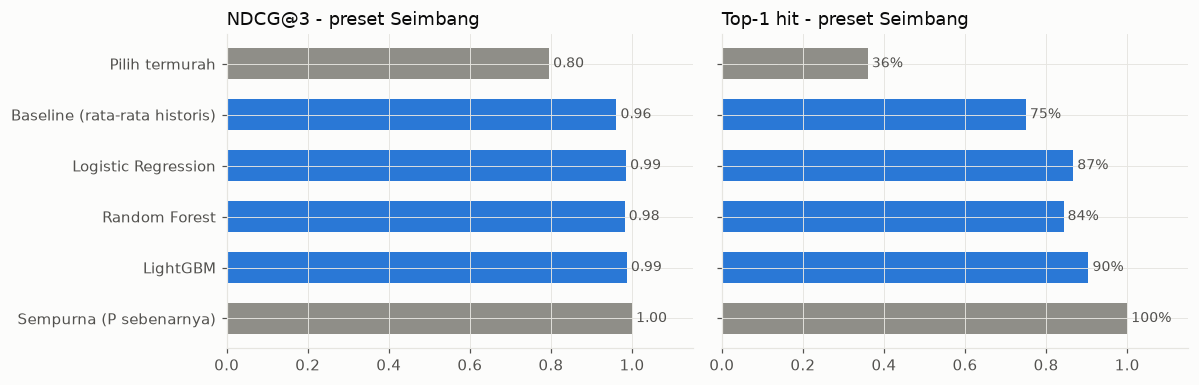

In [7]:
order = ["Pilih termurah", "Baseline (rata-rata historis)", "Logistic Regression", "Random Forest", "LightGBM",
         "Sempurna (P sebenarnya)"]
s = rk[rk["preset"] == "Seimbang"].set_index("strategi").loc[order]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, col, title in [(axes[0], "ndcg@3", "NDCG@3"), (axes[1], "top1_hit", "Top-1 hit")]:
    colors = [MUTED if i in (0, len(order) - 1) else S1 for i in range(len(order))]
    ax.barh(range(len(order)), s[col], color=colors, height=0.6)
    for i, v in enumerate(s[col]):
        ax.text(v + 0.01, i, f"{v:.2f}" if col == "ndcg@3" else f"{v:.0%}", va="center", fontsize=9, color=INK2)
    ax.set_xlim(0, 1.15); ax.set_title(f"{title} - preset Seimbang", loc="left")
axes[0].set_yticks(range(len(order)), order); axes[0].invert_yaxis()
fig.tight_layout()

## 5. Fitur yang paling berpengaruh (model terpilih)

Permutation importance pada data test: seberapa turun ROC-AUC jika satu fitur diacak.

,penurunan_auc
kelonggaran_waktu,0.1487
musim_ramai,0.0328
tingkat_cacat,0.0251
rata_hari_telat,0.0178
hari_tersedia,0.0053
berhasil_musim_ramai,0.0042
qty,0.0027
jumlah_transaksi,0.0019


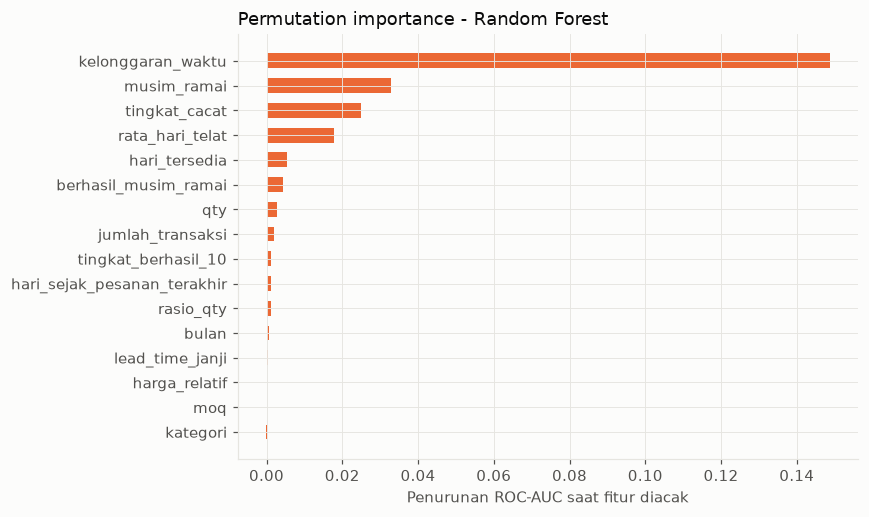

In [8]:
sel = out["fitted"][out["selected"]]
pi = permutation_importance(sel, out["test"][FEATURE_COLUMNS], out["test"]["berhasil"], scoring="roc_auc",
                            n_repeats=5, random_state=0, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURE_COLUMNS).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(imp.index, imp.values, color=S2 if out["selected"] == "random_forest" else S1, height=0.6)
ax.set_xlabel("Penurunan ROC-AUC saat fitur diacak")
ax.set_title(f"Permutation importance - {MODEL_LABELS[out['selected']]}", loc="left")
fig.tight_layout()
imp.sort_values(ascending=False).head(8).to_frame("penurunan_auc")

## 6. Contoh rekomendasi dengan model v1

In [9]:
r = recommend({"material_id": "M01", "qty": 200, "hari_tersedia": 14}, preset="Seimbang")
print("Model:", r["model"], "| kandidat:", r["jumlah_kandidat"])
pd.DataFrame(r["ranking"])[["peringkat", "nama_vendor", "harga_satuan", "lead_time_janji", "p_berhasil", "skor",
                            "jumlah_transaksi", "data_terbatas"]]

Model: v1-random_forest | kandidat: 7


,peringkat,nama_vendor,harga_satuan,lead_time_janji,p_berhasil,skor,jumlah_transaksi,data_terbatas
0,1,Tekstil H,50700,7,0.9111,0.6556,190,False
1,2,Tekstil I,41300,13,0.7703,0.6072,165,False
2,3,Tekstil C,38300,13,0.6239,0.6049,451,False
3,4,Tekstil E,44600,13,0.8657,0.5769,75,False
4,5,Tekstil B,38000,13,0.4940,0.5470,587,False
5,6,Tekstil G,45700,12,0.6856,0.4942,166,False
6,7,Tekstil F,47300,13,0.8080,0.4843,376,False


## Ringkasan dan keputusan

**Model v1 terpilih: Random Forest** (`min_samples_leaf=20`, `max_features=0.5`, 300 pohon), disimpan sebagai `models/model.joblib` (`v1-random_forest`). Model dilatih ulang pada seluruh data (6.075 transaksi s.d. 30 Sep 2026).

1. **Validasi silang (train).** RF 0,796, LightGBM 0,793, LR 0,778, baseline 0,650. LightGBM berada dalam toleransi 0,005 dari RF, sehingga dipilih yang lebih sederhana, yaitu RF. RF juga paling stabil antarlipatan (std 0,012).
2. **Test (Apr–Sep 2026, 1.583 transaksi).** Semua model melampaui target ROC-AUC ≥ 0,75 dan jauh di atas baseline (0,625): LR 0,813, RF 0,813, LightGBM 0,819. Batas atas (oracle) di data ini 0,840, jadi model hanya tertinggal 0,02–0,03 dari prediksi sempurna. Brier RF 0,129 vs baseline 0,163.
3. **Catatan jujur.** Di test, LightGBM sedikit lebih baik dari RF (ROC-AUC +0,006, Top-1 preset Seimbang 90% vs 84%). Model tetap dipilih lewat validasi silang, bukan test, supaya test tidak ikut dipakai memilih model. Selisihnya kecil, dan semua model jauh lebih baik dari baseline maupun "pilih termurah".
4. **Kalibrasi baik.** Kurva kalibrasi RF dan LR mengikuti diagonal. Ini penting karena P(berhasil) dipakai langsung di skor ranking dan ditampilkan ke pengguna.
5. **Ranking (1.464 kebutuhan, 8.570 pasangan kandidat), preset Seimbang.**
   - Pilih termurah: NDCG@3 0,80, Top-1 36%, P(berhasil) pilihan #1 rata-rata 74,7%.
   - Baseline: NDCG@3 0,96, Top-1 75%.
   - **RF: NDCG@3 0,98, Top-1 84%, P(berhasil) pilihan #1 87,5%** dengan harga rata-rata 8,9% di atas termurah.
   - Target "NDCG@3 dan Top-1 lebih baik dari pilih termurah" tercapai di ketiga preset.
6. **Fitur terpenting (permutation importance).** `kelonggaran_waktu` jauh paling dominan, disusul `musim_ramai`, `tingkat_cacat`, dan `rata_hari_telat`. `harga_relatif` dan `moq` hampir tidak berpengaruh pada P(berhasil). Ini sesuai mekanisme generator: harga berkorelasi dengan kualitas vendor, tetapi tidak menentukan hasil secara langsung.

**Keterbatasan evaluasi.**
- Relevansi ranking memakai rumus skor berbobot yang sama dengan sistem. Perbandingan dengan "pilih termurah" mengukur seberapa baik sistem mencapai **tujuan berbobot itu**. Karena itu metrik yang lebih netral juga dilaporkan: P(berhasil) sebenarnya dari pilihan #1, dan selisih harganya.
- Ground truth berasal dari generator sintetis. Pada data nyata Firaza, angka ini perlu diukur ulang.
